# CA1 Build Test and Explain a Tiny Transformer

**Author:** Phyu Sin Lynn (Emi)

## Assigned investigation

The assigned investigation compares a baseline with 4 attention heads against a variant with 2 attention heads.

Both models retain sinusoidal positional encoding, model width 32 and feed-forward width 128. Each receives 160 optimiser updates using the assigned seed 4366.

## Environment and reproducibility setup

This cell imports the libraries used by the model, data preparation, evaluation and plotting code.

The random seed is set to 4366, the value assigned for this coursework. Both training runs will also receive this seed explicitly.

Generated evidence is saved in the CA1_evidence folder. Python and package versions are recorded to document the environment. The model runs on CPU.

In [1]:
import math
import time
import json
import random
import hashlib
import sys
from pathlib import Path

try:
    import numpy as np
    import torch
    from torch import nn
    from torch.nn import functional as F
    import matplotlib
    import matplotlib.pyplot as plt
except ImportError as exc:
    raise RuntimeError(
        "Select the Transformers Lab kernel, then rerun this cell."
    ) from exc

torch.set_num_threads(2) # Keep the tiny CPU workload from using excessive threads.

# Assigned CA1 settings.
d = 6        # assigned digit (sets the shape-trace sizes and the head-count investigation)
SEED = 4366  # assigned seed

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

EVIDENCE = Path("CA1_evidence")
EVIDENCE.mkdir(exist_ok=True)

VERSIONS = {
    "python": sys.version.split()[0],
    "torch": str(torch.__version__),
    "numpy": np.__version__,
    "matplotlib": matplotlib.__version__,
}

def save_json(name, obj):
    (EVIDENCE / name).write_text(
        json.dumps(obj, indent=2, ensure_ascii=False),
        encoding="utf-8",
    )

print("Device: CPU")
print("Packages:", json.dumps(VERSIONS, indent=2))
print("Assigned digit:", d)
print("Assigned seed:", SEED)
print("Evidence folder:", EVIDENCE)

Device: CPU
Packages: {
  "python": "3.11.18",
  "torch": "2.15.0+cpu",
  "numpy": "2.4.6",
  "matplotlib": "3.11.2"
}
Assigned digit: 6
Assigned seed: 4366
Evidence folder: CA1_evidence


## A1 Transformer implementation and tests

This section retains Lab 3's causal Transformer with separate learned Q/K/V projections, sinusoidal positional encoding, layer normalisation, residual connections and feed-forward layers.

The implementation is examined using an assigned tensor-shape trace, attention checks, a full-model future-token test and a single-token boundary test.

### Causal self-attention

In [2]:
class CausalAttention(nn.Module):
    def __init__(self, width=32, heads=4):
        super().__init__()
        if width <= 0 or heads <= 0 or width % heads != 0:
            raise ValueError('width must be divisible by a positive head count')

        self.heads = heads
        self.d_head = width // heads

        # One Linear layer calculates three projections; chunk separates them.
        self.qkv = nn.Linear(width, 3 * width)

        # After heads are joined, this learned layer mixes their information.
        self.proj = nn.Linear(width, width)

    def project_qkv(self, x):
        return self.qkv(x).chunk(3, dim=-1)

    def forward(self, x, causal=True):
        B, T, D = x.shape
        q, k, v = self.project_qkv(x)  # Each starts as [B,T,D].

        # Put heads before positions: each head compares its own D/H features.
        q, k, v = [z.view(B, T, self.heads, self.d_head).transpose(1, 2)
                   for z in (q, k, v)]

        # Compare each query with the keys in its head, then scale.
        scores = q @ k.transpose(-2, -1) / math.sqrt(self.d_head)

        # Block future positions before converting scores to weights.
        if causal:
            blocked = torch.triu(torch.ones(T, T, device=x.device,
                                           dtype=torch.bool), diagonal=1)
            # [1,1,T,T] broadcasts the same causal rule across batch and heads.
            scores = scores.masked_fill(blocked[None, None, :, :], float('-inf'))

        weights = scores.softmax(dim=-1)  # [B,H,T,T], over available keys.

        # Mix V within each head, then join heads into the original D features.
        out = (weights @ v).transpose(1, 2).contiguous().view(B, T, D)

        # Mix information across the joined heads.
        return self.proj(out), weights


### Transformer block


In [3]:
class Block(nn.Module):
    def __init__(self, width=32, heads=4, ff_hidden=None,
                 attention_class=CausalAttention):
        super().__init__()

        self.ln1 = nn.LayerNorm(width)
        self.ln2 = nn.LayerNorm(width)

        # Passing a class lets the model use SeparateAttention.
        self.attn = attention_class(width, heads)

        # The feed-forward network expands each token, then returns to model width.
        hidden = 4 * width if ff_hidden is None else ff_hidden
        self.ff = nn.Sequential(nn.Linear(width, hidden), nn.GELU(),
                                nn.Linear(hidden, width))

    def forward(self, x, causal=True):
        # Attention sublayer: normalise, mix permitted tokens, then add the residual.
        attended, weights = self.attn(self.ln1(x), causal)
        x = x + attended  # Preserve the original representation through a residual path.

        # Feed-forward sublayer: transform each token separately, then add the residual.
        x = x + self.ff(self.ln2(x))  # Same shape [B,T,D] on both sides.

        return x, weights


### Complete Transformer

In [4]:
class TinyTransformer(nn.Module):
    def __init__(self, vocab_size, width=32, heads=4, context=32,
                 use_positions=True, ff_hidden=None,
                 attention_class=CausalAttention):
        super().__init__()
        if width <= 0 or width % 2:
            raise ValueError('This sinusoidal implementation requires even width')

        self.context = context
        self.use_positions = use_positions

        # Token embedding: a learned feature vector for each character ID.
        self.embedding = nn.Embedding(vocab_size, width)

        # Fixed sinusoidal positional encoding.
        positions = torch.arange(context).float().unsqueeze(1)
        # Each pair of features varies with position at a different frequency.
        rates = torch.exp(torch.arange(0, width, 2).float()
                          * (-math.log(10000.) / width))
        pe = torch.zeros(context, width)
        pe[:, 0::2] = torch.sin(positions * rates)
        pe[:, 1::2] = torch.cos(positions * rates)
        self.register_buffer('pe', pe)  # Saved state, not a trainable parameter.

        # Attention and feed-forward sublayers, each with a residual connection.
        self.block = Block(width, heads, ff_hidden, attention_class)

        # Final layer normalisation.
        self.norm = nn.LayerNorm(width)

        # Vocabulary output layer: one score for each possible next character.
        self.output = nn.Linear(width, vocab_size)

    def forward(self, ids, causal=True):
        if ids.shape[1] > self.context:
            raise ValueError('Sequence exceeds context length')

        # Token embedding.
        x = self.embedding(ids)  # [B,T] IDs become [B,T,D] features.

        # Add positional encoding to the token features.
        if self.use_positions:
            x = x + self.pe[:ids.shape[1]]  # [T,D] broadcasts over B.

        # Attention + residual, then feed-forward + residual.
        x, weights = self.block(x, causal)

        # Final layer normalisation, then the vocabulary output layer.
        return self.output(self.norm(x)), weights  # Logits [B,T,V], not probabilities.


### Separate query key and value projections

In [5]:
class SeparateAttention(CausalAttention):
    def __init__(self, width=32, heads=4):
        super().__init__(width, heads)

        # Remove the combined projection before defining separate Q, K, and V layers.
        del self.qkv
        self.q_proj = nn.Linear(width, width)  
        self.k_proj = nn.Linear(width, width)  
        self.v_proj = nn.Linear(width, width)  

    def project_qkv(self, x):
        return self.q_proj(x), self.k_proj(x), self.v_proj(x)  # [B,T,D] each

### Assigned tensor shape trace

With the assigned digit d = 6:

| Setting | Calculation | Value |
|---|---|---|
| Batch size B | 1 + (d % 2) | 1 |
| Sequence length T | 4 + (d % 3) | 4 |
| Model width D | Assigned | 32 |
| Attention heads H | Assigned | 4 |
| Features per head | D/H | 8 |

In [6]:
def trace_shapes(model, ids):
    model.eval()

    with torch.no_grad():
        embedded = model.embedding(ids)
        x = (
            embedded + model.pe[:ids.shape[1]]
            if model.use_positions else embedded
        )

        # Each projection starts with shape [B,T,D].
        q, k, v = model.block.attn.project_qkv(
            model.block.ln1(x)
        )

        B, T, D = q.shape
        H = model.block.attn.heads
        d_head = model.block.attn.d_head

        # Split features among heads and move H before T.
        q_heads, k_heads, v_heads = [
            z.view(B, T, H, d_head).transpose(1, 2)
            for z in (q, k, v)
        ]

        block_out, weights = model.block(x)
        logits, _ = model(ids)

    shapes = {
        "IDs [B,T]": list(ids.shape),
        "Embeddings [B,T,D]": list(embedded.shape),
        "Q before split [B,T,D]": list(q.shape),
        "K before split [B,T,D]": list(k.shape),
        "V before split [B,T,D]": list(v.shape),
        "Q after split [B,H,T,D/H]": list(q_heads.shape),
        "K after split [B,H,T,D/H]": list(k_heads.shape),
        "V after split [B,H,T,D/H]": list(v_heads.shape),
        "Weights [B,H,T_query,T_key]": list(weights.shape),
        "Block output [B,T,D]": list(block_out.shape),
        "Logits [B,T,V]": list(logits.shape),
    }

    for label, shape in shapes.items():
        print(f"{label:34s} {shape}")

    return shapes


# Assigned A1 dimensions.
B = 1 + (d % 2)
T = 4 + (d % 3)

# Lab 3 fixed vocabulary: newline, space, '.', ',' and a-z (checked in A3).
TRACE_VOCAB = 30

torch.manual_seed(SEED)

probe = TinyTransformer(
    vocab_size=TRACE_VOCAB,
    width=32,
    heads=4,
    context=24,
    use_positions=True,
    attention_class=SeparateAttention,
)

ids = torch.arange(1, B * T + 1).reshape(B, T) % TRACE_VOCAB

assert isinstance(probe.block.attn, SeparateAttention)

ca1_shapes = trace_shapes(probe, ids)

IDs [B,T]                          [1, 4]
Embeddings [B,T,D]                 [1, 4, 32]
Q before split [B,T,D]             [1, 4, 32]
K before split [B,T,D]             [1, 4, 32]
V before split [B,T,D]             [1, 4, 32]
Q after split [B,H,T,D/H]          [1, 4, 4, 8]
K after split [B,H,T,D/H]          [1, 4, 4, 8]
V after split [B,H,T,D/H]          [1, 4, 4, 8]
Weights [B,H,T_query,T_key]        [1, 4, 4, 4]
Block output [B,T,D]               [1, 4, 32]
Logits [B,T,V]                     [1, 4, 30]


### Attention implementation checks

In [7]:
def check_attention(attention_class):
    torch.manual_seed(7)
    layer = attention_class(width=8, heads=2).eval()
    x = torch.randn(2, 4, 8, requires_grad=True)
    y, w = layer(x)

    # Check output shapes and valid attention weights.
    assert y.shape == (2, 4, 8), 'Output shape'
    assert w.shape == (2, 2, 4, 4), 'Attention shape'
    assert torch.isfinite(y).all() and torch.isfinite(w).all(), 'Finite forward values'
    assert torch.allclose(w.sum(-1), torch.ones(2, 2, 4), atol=1e-6), 'Row sums'

    # Check that the causal mask blocks future positions.
    future = torch.triu(torch.ones(4, 4, dtype=torch.bool), diagonal=1)
    assert torch.count_nonzero(w[..., future]).item() == 0, 'Future weights must be zero'

    # Change a future input and compare the earlier outputs.
    changed = x.detach().clone()
    changed[:, -1] += 10  # Earlier outputs must ignore this future change.
    with torch.no_grad():
        y_changed, _ = layer(changed)

    assert torch.allclose(y[:, :-1], y_changed[:, :-1], atol=1e-5, rtol=0), 'Causality'

    # Check that gradients reach the inputs and learned parameters.
    y.square().mean().backward()
    assert x.grad is not None and torch.isfinite(x.grad).all(), 'Input gradient'
    for name, p in layer.named_parameters():
        assert p.grad is not None and torch.isfinite(p.grad).all(), f'Gradient: {name}'

    # Reject a width that cannot be split equally across the heads.
    try:
        attention_class(width=10, heads=3)
    except ValueError:
        pass
    else:
        raise AssertionError('Invalid width/head combination should be rejected')

    return {'shape': True, 'row_sums': True, 'future_mask': True,
            'causality': True, 'finite_gradients': True, 'invalid_width': True}

print('Supplied attention:', check_attention(CausalAttention))


Supplied attention: {'shape': True, 'row_sums': True, 'future_mask': True, 'causality': True, 'finite_gradients': True, 'invalid_width': True}


In [8]:
attention_ready = False  # Rerunning this cell must not retain an old PASS.

attention_checks = check_attention(SeparateAttention)
inspected = SeparateAttention(width=8, heads=2)
layers = [inspected.q_proj, inspected.k_proj, inspected.v_proj]

# Inspect the three projections and check that their weights are independent.
assert all(isinstance(layer, nn.Linear) for layer in layers), 'Use three Linear layers'
assert len({id(layer.weight) for layer in layers}) == 3, 'Use independent weights'
assert not hasattr(inspected, 'qkv'), 'Remove the unused combined projection'

# Record a successful check and display the result.
attention_ready = True
print('SeparateAttention: PASS', attention_checks)


SeparateAttention: PASS {'shape': True, 'row_sums': True, 'future_mask': True, 'causality': True, 'finite_gradients': True, 'invalid_width': True}


### Causal attention heatmap

Darker blue indicates a larger attention weight. The white region above the diagonal represents future positions with zero weight.
The model is untrained, so this plot illustrates masking behaviour.

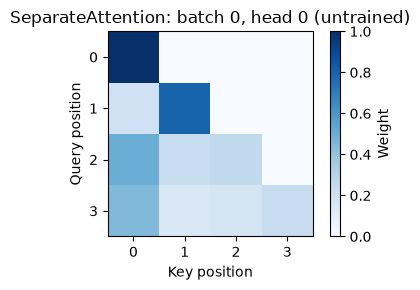

In [9]:
if attention_ready:
    torch.manual_seed(SEED)  # Reproducible untrained weights for this plot.
    student_probe = TinyTransformer(12, width=8, heads=2, context=8,
                                    attention_class=SeparateAttention).eval()

    with torch.no_grad():
        _, student_weights = student_probe(ids)

    # Display one head: rows are queries, and columns are keys.
    plt.figure(figsize=(4, 3))
    plt.imshow(student_weights[0, 0].numpy(), vmin=0, vmax=1, cmap='Blues')
    plt.xlabel('Key position')
    plt.ylabel('Query position')
    plt.xticks(range(4))
    plt.yticks(range(4))
    plt.title('SeparateAttention: batch 0, head 0 (untrained)')
    plt.colorbar(label='Weight')
    plt.tight_layout()
    plt.show()
else:
    print('Run the A1 attention checks before plotting.')


### Full model future-token test

In [10]:
causal_ready = False
causal_evidence = {}

if attention_ready:
    torch.manual_seed(11)

    # Use the SeparateAttention class inside the model.
    probe = TinyTransformer(12, width=8, heads=2, context=8,
                            attention_class=SeparateAttention).eval()

    a = torch.tensor([[1, 2, 3, 4]])
    b = torch.tensor([[1, 2, 3, 9]])

    with torch.no_grad():
        reference_a, _ = probe(a, causal=False)
        reference_b, _ = probe(b, causal=False)

        before, _ = probe(a, causal=True)  # Causal mask on.
        after, _ = probe(b, causal=True)

    # Measure changes only at the earlier positions.
    reference_change = (reference_a[:, :3] - reference_b[:, :3]).abs().max().item()
    masked_change = (before[:, :3] - after[:, :3]).abs().max().item()
    TOLERANCE = 1e-5
    causal_ready = masked_change <= TOLERANCE

    causal_evidence = {'unmasked_change': reference_change,
                       'masked_change': masked_change, 'tolerance': TOLERANCE,
                       'passed': causal_ready}

    print(f'Unmasked earlier-logit change: {reference_change:.8f}')
    print(f'Masked earlier-logit change: {masked_change:.8f}')
    print(f'Tolerance: {TOLERANCE}; future-token test: {"PASS" if causal_ready else "FAIL"}')
else:
    print('Run the A1 attention checks first.')


Unmasked earlier-logit change: 0.12253469
Masked earlier-logit change: 0.00000000
Tolerance: 1e-05; future-token test: PASS


### Single token boundary test

In [11]:
torch.manual_seed(SEED)

boundary_probe = TinyTransformer(
    vocab_size=TRACE_VOCAB,
    width=32,
    heads=4,
    context=24,
    use_positions=True,
    attention_class=SeparateAttention,
).eval()

boundary_ids = torch.tensor([[1]], dtype=torch.long)

with torch.no_grad():
    boundary_logits, boundary_weights = boundary_probe(
        boundary_ids,
        causal=True,
    )

# One batch, one position, one score per vocabulary item.
assert boundary_logits.shape == (1, 1, TRACE_VOCAB)

# One batch, four heads, one query and one key.
assert boundary_weights.shape == (1, 4, 1, 1)

assert torch.isfinite(boundary_logits).all()
assert torch.isfinite(boundary_weights).all()

# The only available key must receive all the attention.
assert torch.allclose(
    boundary_weights,
    torch.ones_like(boundary_weights),
    atol=1e-6,
    rtol=0,
)

print("Boundary logits shape:", list(boundary_logits.shape))
print("Boundary weights shape:", list(boundary_weights.shape))
print("Boundary attention weights:")
print(boundary_weights)
print("Single-token boundary test: PASS")

Boundary logits shape: [1, 1, 30]
Boundary weights shape: [1, 4, 1, 1]
Boundary attention weights:
tensor([[[[1.]],

         [[1.]],

         [[1.]],

         [[1.]]]])
Single-token boundary test: PASS


### A1 Explanation

The model I trained uses SeparateAttention, with three separate layers to create Q, K and V. My assigned shape test uses one sequence of four tokens: B=1 and T=4. The model width is 32, divided between four heads, so each head receives 8 features.

Q, K and V each change from [1,4,32] before splitting to [1,4,4,8] after splitting. The attention weights have shape [1,4,4,4]: one batch, four heads, four query positions and four key positions. The Transformer block keeps shape [1,4,32]. The logits have shape [1,4,30], meaning 30 raw next-token scores at each position, one for each character in the fixed vocabulary. The trace uses the same 30-character vocabulary as training, which the A3 data cell checks.

For the future-token test, I changed only the final input token and compared the earlier logits. Without the causal mask, the largest change was 0.12253469. With the mask, it was 0.00000000, below the 1e-5 tolerance. This shows that the earlier positions ignored the changed future token in this test.

The T=1 boundary test contains only one token. There are no earlier tokens, and the current token must remain available to attend to. Each of the four heads therefore gives it attention weight 1. The attention weights have shape [1,4,1,1], the logits have shape [1,1,30]. Both outputs contain only finite values.

Together, the tests check the expected shapes, attention rows summing to 1, zero attention to future positions, finite gradients and rejection of incompatible width/head combinations. They provide
evidence that the implementation behaves correctly on the tested inputs. They do not show that the model predicts well or guarantee correctness for every possible input; prediction quality is assessed through training and validation.

## A2 Fault diagnosis and correction

This isolated four-position attention example compares two masks applied to the same attention scores before softmax.

The faulty mask uses diagonal=0, blocking the current position as well as future positions. The repaired mask uses diagonal=1, blocking only future positions.

Both weight matrices are displayed. The repaired weights are checked for finite values, row sums of 1 and zero attention to future tokens. The faulty example does not modify the model's attention implementation.

In [12]:
# Isolated example: use identical scores for both masks.
torch.manual_seed(SEED)

T = 4
example_q = torch.randn(T, 8)
example_k = torch.randn(T, 8)
example_scores = example_q @ example_k.T / math.sqrt(8)

# Fault: blocks the diagonal as well as future positions.
faulty_mask = torch.triu(
    torch.ones(T, T, dtype=torch.bool),
    diagonal=0,
)

faulty_weights = example_scores.masked_fill(
    faulty_mask, float("-inf")
).softmax(dim=-1)

print("Faulty attention weights:")
print(faulty_weights)
print(
    "Faulty weights all finite:",
    torch.isfinite(faulty_weights).all().item(),
)

# Repair: leave the current position available.
repaired_mask = torch.triu(
    torch.ones(T, T, dtype=torch.bool),
    diagonal=1,
)

repaired_weights = example_scores.masked_fill(
    repaired_mask, float("-inf")
).softmax(dim=-1)

print("\nRepaired attention weights:")
print(repaired_weights)
print("Repaired row sums:", repaired_weights.sum(dim=-1))

# Validate the repaired result.
assert torch.isfinite(repaired_weights).all()

assert torch.allclose(
    repaired_weights.sum(dim=-1),
    torch.ones(T),
    atol=1e-6,
    rtol=0,
)

assert torch.count_nonzero(
    repaired_weights[repaired_mask]
).item() == 0

print("A2 repaired-mask checks: PASS")

Faulty attention weights:
tensor([[   nan,    nan,    nan,    nan],
        [1.0000, 0.0000, 0.0000, 0.0000],
        [0.4246, 0.5754, 0.0000, 0.0000],
        [0.9216, 0.0599, 0.0184, 0.0000]])
Faulty weights all finite: False

Repaired attention weights:
tensor([[1.0000, 0.0000, 0.0000, 0.0000],
        [0.1004, 0.8996, 0.0000, 0.0000],
        [0.1484, 0.2011, 0.6505, 0.0000],
        [0.6634, 0.0431, 0.0133, 0.2802]])
Repaired row sums: tensor([1.0000, 1.0000, 1.0000, 1.0000])
A2 repaired-mask checks: PASS


### A2 Explanation

The faulty mask uses diagonal=0, blocking each token from attending to itself and future tokens. For the first token, every key is blocked, so all scores in its row become negative infinity. Softmax cannot normalise this row into a valid probability distribution, producing nan values. Consequently, the faulty finite-value check returns False.

Changing the mask to diagonal=1 leaves the current position available while continuing to block future positions. Both examples use identical attention scores, so the differences result from the mask correction.

The repaired first row is [1, 0, 0, 0] because the first token can attend only to itself. All repaired weights are finite, every row sums to 1 within tolerance 1e-6, and all future-token weights are zero. These checks pass, confirming the expected masking behaviour for this example.

Shape checks alone would miss this fault because both matrices have shape [4,4]. Correct dimensions do not guarantee valid numerical values or correct masking behaviour.

The faulty example is isolated from the model and is not required to pass a finite-value assertion, allowing Run All to finish.

## A3 Data, training and reload

### Data preparation

In [13]:
# Build distinct training and validation documents from the templates.
ROOMS = ['alpha', 'beta', 'gamma', 'delta', 'omega', 'sigma']
TIMES = ['nine', 'ten', 'eleven', 'twelve', 'one', 'two']
train_templates = ['the {room} lab opens at {hour}.',
                   'visit {room} lab at {hour}.',
                   'at {hour}, the {room} lab is open.']
val_templates = ['opening time for {room} lab is {hour}.']

def make_docs(templates, prefix):
    return [{'id':f'{prefix}-{t}-{r}-{h}', 'text':tpl.format(room=room, hour=hour)+'\n'}
            for t, tpl in enumerate(templates)
            for r, room in enumerate(ROOMS) for h, hour in enumerate(TIMES)]

train_docs = make_docs(train_templates, 'train')
val_docs = make_docs(val_templates, 'val')

# Fixed character vocabulary; no statistics are fitted on validation text.
chars = '\n .,abcdefghijklmnopqrstuvwxyz'
stoi = {c:i for i,c in enumerate(chars)}
itos = dict(enumerate(chars))

def encode(text):
    return [stoi[c] for c in text]

def decode(ids):
    return ''.join(itos[int(i)] for i in ids)

CONTEXT = 24

def window_lists(docs, context=CONTEXT):
    xs, ys = [], []
    for doc in docs:  # Never create a window crossing document boundaries.
        tokens = encode(doc['text'])
        for start in range(len(tokens) - context):
            xs.append(tokens[start:start+context])
            # Each target is the character immediately after its input.
            ys.append(tokens[start+1:start+context+1])

    if not xs:
        raise ValueError('No windows: each document needs context + 1 characters')

    return xs, ys

def windows(docs, context=CONTEXT):
    xs, ys = window_lists(docs, context)
    return torch.tensor(xs, dtype=torch.long), torch.tensor(ys, dtype=torch.long)

train_x, train_y = windows(train_docs)
val_x, val_y = windows(val_docs)

# Check the split before inspecting an example.
assert {d['text'] for d in train_docs}.isdisjoint({d['text'] for d in val_docs})
assert len(train_x) and len(val_x)
assert len(chars) == TRACE_VOCAB, 'A1 trace vocabulary must match training'

print('Documents:', len(train_docs), len(val_docs))
print('Windows:', tuple(train_x.shape), tuple(val_x.shape))
print('Input: ', repr(decode(train_x[0])))
print('Target:', repr(decode(train_y[0])))

# Check that each target is the next character in its input sequence.
assert torch.equal(train_x[:, 1:], train_y[:, :-1])
assert torch.equal(val_x[:, 1:], val_y[:, :-1])

# Record documents that are too short to produce a complete window.
no_window_docs = {label: sum(len(encode(d['text'])) <= CONTEXT for d in docs)
                  for label, docs in [('train', train_docs), ('validation', val_docs)]}
print('Documents too short for a full input plus target:', no_window_docs)

# Save the split and window counts as evidence.
save_json('split.json', {'train': train_docs, 'validation': val_docs,
                         'chars': chars, 'context': CONTEXT,
                         'documents_without_windows': no_window_docs,
                         'window_counts': {'train': len(train_x), 'validation': len(val_x)}})


Documents: 108 36
Windows: (507, 24) (432, 24)
Input:  'the alpha lab opens at n'
Target: 'he alpha lab opens at ni'
Documents too short for a full input plus target: {'train': 19, 'validation': 0}


### Training helpers and baseline training

In [14]:
# SEED and d were set in the setup cell from the assigned values.
room = ROOMS[d % 6]
PROMPT = f'the {room} lab '

print("Assigned seed:", SEED)
print("Batch seed:", SEED + 1)
print("Generation prompt:", repr(PROMPT))

Assigned seed: 4366
Batch seed: 4367
Generation prompt: 'the alpha lab '


In [15]:
@torch.no_grad()
def evaluate(model, xs, ys, batch_size=128):
    model.eval()
    total_loss, correct, count = 0., 0, 0

    for start in range(0, len(xs), batch_size):
        xb, yb = xs[start:start+batch_size], ys[start:start+batch_size]
        logits, _ = model(xb)

        # [B,T,V] -> [B*T,V]; [B,T] -> [B*T]. Each row is one target position.
        total_loss += F.cross_entropy(logits.flatten(0, 1), yb.flatten(),
                                      reduction='sum').item()
        correct += (logits.argmax(-1) == yb).sum().item()
        count += yb.numel()

    if not count:
        raise ValueError('Evaluation needs at least one target')

    # Average over all target positions, not over batches.
    return {'loss': total_loss / count, 'accuracy': correct / count,
            'correct': correct, 'targets': count}


In [16]:
@torch.no_grad()
def generate(model, prompt, new_chars=40):
    if not prompt or new_chars < 0:
        raise ValueError('Use a non-empty prompt and a non-negative generation length')

    model.eval()
    output_ids = encode(prompt)

    # Predict from the current context, then append one character.
    for _ in range(new_chars):
        window = torch.tensor([output_ids[-model.context:]], dtype=torch.long)
        logits, _ = model(window)

        output_ids.append(logits[0, -1].argmax().item())

    return decode(output_ids)

# Diagnostic fingerprint: compare model states without printing every tensor.
def state_digest(model):
    digest = hashlib.sha256()
    for name, value in model.state_dict().items():
        digest.update(name.encode('utf-8'))
        digest.update(value.detach().cpu().contiguous().numpy().tobytes())

    return digest.hexdigest()


### Train the baseline

In [17]:
def train_run(use_positions=True, steps=320, seed=42, heads=4, ff_hidden=128,
              attention_class=CausalAttention, width=32, label=None):
    if steps not in (80, 160, 320):
        raise ValueError('Use 320 updates, or 160 or 80 for both runs on a slower CPU')

    # Set up the model from a reproducible starting point.
    torch.manual_seed(seed)
    config = {'vocab_size': len(chars), 'width': width, 'heads': heads,
              'context': CONTEXT, 'use_positions': use_positions, 'ff_hidden': ff_hidden}
    model = TinyTransformer(**config, attention_class=attention_class)

    # Diagnostics: verify the chosen attention class and retain the initial state.
    assert isinstance(model.block.attn, attention_class), 'Training must use the selected class'
    initial_state = {name: value.detach().clone() for name, value in model.state_dict().items()}
    initial_digest = state_digest(model)

    # Prepare parameter updates and a separate random generator for batches.
    optimiser = torch.optim.AdamW(model.parameters(), lr=0.003, weight_decay=0.01)
    batch_rng = torch.Generator().manual_seed(seed + 1)

    # Logging: identify this run and record its progress.
    batch_digest = hashlib.sha256()
    # Use the caller's label; fall back to the head count only if none is given.
    label = label or ('Baseline' if heads == 4 else 'Variant')
    progress_name = f'progress_{label.lower()}.json'
    started = time.perf_counter()
    save_json(progress_name, {'run': label, 'stage': 'initial evaluation', 'completed_updates': 0})

    # Measure loss and generated text before any parameter update.
    initial = evaluate(model, train_x, train_y)
    initial_val = evaluate(model, val_x, val_y)
    initial_text = generate(model, PROMPT)

    # Record and display the starting measurements.
    history = [{'step': 0, 'batch_loss': initial['loss'], 'val_loss': initial_val['loss']}]
    print(f"\n{label}: initial train loss {initial['loss']:.4f}, "
          f"initial val loss {initial_val['loss']:.4f}", flush=True)

    # Training loop: one batch and one parameter update per iteration.
    for step in range(1, steps + 1):
        model.train()
        idx = torch.randint(len(train_x), (32,), generator=batch_rng)

        # Diagnostic fingerprint: later verify that both runs used identical batches.
        batch_digest.update(idx.numpy().tobytes())

        # Forward pass through the Transformer, then loss against next-character targets.
        logits, _ = model(train_x[idx])
        loss = F.cross_entropy(logits.flatten(0, 1), train_y[idx].flatten())

        # Stop if the loss becomes invalid.
        if not torch.isfinite(loss):
            raise RuntimeError(f'{label}: non-finite loss at update {step}')

        # Backpropagation and parameter update.
        optimiser.zero_grad()  # Clear gradients from the previous batch.
        loss.backward()       # Differentiate through the complete model.
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimiser.step()      # Apply the learned-parameter update.

        # Evaluate and log progress every 40 updates.
        if step % 40 == 0:
            validation = evaluate(model, val_x, val_y)

            history.append({'step': step, 'batch_loss': loss.item(),
                            'val_loss': validation['loss']})
            elapsed = time.perf_counter() - started
            save_json(progress_name, {'run': label, 'stage': 'training',
                                     'completed_updates': step, 'seconds': elapsed,
                                     'history': history})

            print(f"{label}: {step}/{steps} updates; train loss {loss.item():.4f}; "
                  f"val loss {validation['loss']:.4f}; elapsed {elapsed:.1f}s",
                  flush=True)

    # After training: measure which learned parameters changed.
    changes = {name: (p.detach() - initial_state[name]).abs().max().item()
               for name, p in model.named_parameters()}

    # Collect configuration, diagnostics, final metrics, and generated text.
    result = {'positions': use_positions, 'steps': steps, 'completed_updates': steps,
              'seed': seed, 'batch_seed': seed + 1, 'heads': heads, 'ff_hidden': ff_hidden,
              'config': config, 'attention_class': attention_class.__name__,
              'parameter_count': sum(p.numel() for p in model.parameters()),

              'optimiser': 'AdamW', 'learning_rate': 0.003, 'weight_decay': 0.01,
              'batch_size': 32, 'gradient_clip': 1.0,

              'initial_state_sha256': initial_digest,
              'batch_sequence_sha256': batch_digest.hexdigest(),

              'initial_validation': initial_val, 'train': evaluate(model, train_x, train_y),
              'validation': evaluate(model, val_x, val_y), 'history': history,

              'parameter_max_abs_changes': changes,
              'pe_unchanged': torch.equal(model.pe, initial_state['pe']),

              'generation': {'prompt': PROMPT, 'new_chars': 40, 'decoding': 'greedy',
                             'before': initial_text, 'after': generate(model, PROMPT)}}

    result['seconds'] = time.perf_counter() - started

    # Final checks: learned parameters changed, while the fixed position buffer did not.
    assert any(delta > 0 for delta in changes.values()), 'No learned parameter changed'
    assert result['pe_unchanged'], 'Fixed positional buffer changed'

    # Save the completion record, then return the trained model and its evidence.
    save_json(progress_name, {'run': label, 'stage': 'complete',
                             'completed_updates': steps, 'seconds': result['seconds']})

    return model, result


In [18]:
if not (attention_ready and causal_ready):
    raise RuntimeError('Complete and rerun the A1 checks first.')

# Recheck the attention implementation before training.
check_attention(SeparateAttention)

ACTIVE_ATTENTION = SeparateAttention
STEPS = 160

baseline, base_result = train_run(
    True,
    steps=160,
    seed=SEED,
    heads=4,
    ff_hidden=128,
    attention_class=ACTIVE_ATTENTION,
    width=32,
    label='Baseline'
)

# Confirm the assigned baseline settings.
assert base_result['completed_updates'] == 160
assert base_result['seed'] == 4366
assert base_result['batch_seed'] == 4367
assert base_result['heads'] == 4
assert base_result['ff_hidden'] == 128
assert base_result['positions'] is True
assert base_result['attention_class'] == 'SeparateAttention'

# Save baseline results now; B1 will add the variant later.
save_json('results.json', {
    'baseline': base_result,
    'versions': VERSIONS,
    'causal_check': causal_evidence
})

print('\nBaseline summary')
print('Completed updates:', base_result['completed_updates'])
print('Parameter count:', base_result['parameter_count'])
print('Final training loss:', base_result['train']['loss'])
print('Initial validation loss:', base_result['initial_validation']['loss'])
print('Final validation loss:', base_result['validation']['loss'])
print('Validation accuracy:', base_result['validation']['accuracy'])
print('Elapsed seconds:', base_result['seconds'])

largest_change = max(
    base_result['parameter_max_abs_changes'].values()
)
print('Largest parameter change:', largest_change)
print('Fixed position buffer unchanged:', base_result['pe_unchanged'])


Baseline: initial train loss 3.6246, initial val loss 3.6321
Baseline: 40/160 updates; train loss 1.2632; val loss 2.4999; elapsed 0.4s
Baseline: 80/160 updates; train loss 0.6347; val loss 2.8480; elapsed 0.6s
Baseline: 120/160 updates; train loss 0.3410; val loss 3.1937; elapsed 0.9s
Baseline: 160/160 updates; train loss 0.2548; val loss 3.4248; elapsed 1.1s

Baseline summary
Completed updates: 160
Parameter count: 14718
Final training loss: 0.24812477407762676
Initial validation loss: 3.63206985850393
Final validation loss: 3.424808031246986
Validation accuracy: 0.4130979938271605
Elapsed seconds: 1.2020719998981804
Largest parameter change: 0.4085529148578644
Fixed position buffer unchanged: True


### Save and reload the baseline

In [19]:
# Save learned weights, fixed buffers, and the configuration needed to rebuild the model.
torch.save(baseline.state_dict(), EVIDENCE / 'baseline.pt')
save_json('baseline_config.json', {'config': base_result['config'], 'chars': chars,
                                   'attention_class': base_result['attention_class']})

# Read the configuration and check its vocabulary and attention class.
saved = json.loads((EVIDENCE / 'baseline_config.json').read_text(encoding='utf-8'))
assert saved['chars'] == chars, 'Vocabulary order must match the saved weights'
known_attention = {'SeparateAttention': SeparateAttention}
if saved['attention_class'] not in known_attention:
    raise ValueError('Define the saved attention class before reloading')

# Rebuild the architecture, then restore its saved state.
reloaded = TinyTransformer(**saved['config'],
                           attention_class=known_attention[saved['attention_class']])
reloaded.load_state_dict(torch.load(EVIDENCE / 'baseline.pt',
                                    map_location='cpu', weights_only=True))

# Compare both models on the same validation inputs.
baseline.eval()
reloaded.eval()
with torch.no_grad():
    expected, _ = baseline(val_x[:2])
    actual, _ = reloaded(val_x[:2])

# Diagnostic check: reloading should preserve the logits.
reload_difference = (expected - actual).abs().max().item()
reload_tolerance = 1e-6
assert torch.allclose(expected, actual, atol=reload_tolerance, rtol=0), 'Reload mismatch'

# Save the reload evidence and display the result.
save_json('reload_check.json', {'max_abs_logit_difference': reload_difference,
                                'tolerance': reload_tolerance, 'passed': True,
                                'validation_windows': [0, 1]})

print(f'Reload logit difference: {reload_difference:.8f}; '
      f'tolerance: {reload_tolerance}; PASS')
print('Saved: baseline.pt, baseline_config.json, and reload_check.json')


Reload logit difference: 0.00000000; tolerance: 1e-06; PASS
Saved: baseline.pt, baseline_config.json, and reload_check.json


### A3 Explanation

The unchanged Lab 3 corpus contains 108 training documents and 36 validation documents, producing 507 training windows and 432 validation windows. Each window contains 24 input characters and 24 corresponding targets. Nineteen training documents are too short to produce a complete window.

The displayed input is 'the alpha lab opens at n', and its target is 'he alpha lab opens at ni'. Each target is shifted one character ahead, so the first input character 't' has target 'h'. This teaches next-character prediction. Using unshifted targets would instead reward copying the current character.

Whole documents are separated before overlapping windows are created, and no window crosses a document boundary. Randomly splitting overlapping windows could place nearly identical text from the same document into both sets, making validation performance overly optimistic. Validation uses a different wording template but shares room names and vocabulary with training, so it tests limited generalisation rather than general language understanding.

The baseline uses SeparateAttention with independent learned Q/K/V projections, width 32, four heads, feed-forward width 128 and sinusoidal positional encoding. It trains from random weights for 160 optimiser updates using model seed 4366 and independent batch-generator seed 4367.

Training retains Lab 3's batch size 32, AdamW learning rate 0.003, weight decay 0.01 and gradient clipping at 1.0. zero_grad clears previous gradients, backward calculates gradients, and optimiser.step updates learned parameters. The helper records parameter changes and verifies that the fixed positional buffer remains unchanged.

Evaluation uses no_grad and makes no optimiser updates. Loss is summed over all target positions and divided by their total count, giving a smaller final batch the correct weight. Accuracy measures individual next-character predictions, including spaces and punctuation.

For reload verification, baseline.pt stores the parameters and persistent buffers. baseline_config.json records the architecture, attention-class name and vocabulary order. The reload reconstructs the saved architecture, checks the vocabulary order and restores
the state_dict.

Both models are evaluated on the same two validation windows, val_x[:2]. The maximum absolute logit difference is displayed above and saved in reload_check.json. The assertion requires agreement within absolute tolerance 1e-6, with relative tolerance 0.

Comparing complete logits checks every vocabulary score at every tested position. Matching one greedy completion would be weaker evidence because different scores can select the same character. A passing reload check demonstrates numerical agreement on the tested windows, not correctness for every possible input.

These saved files support inference reload. Resuming the exact training trajectory would additionally require optimiser and random-generator states.

## B1 Controlled investigation

### B1 Hypothesis

I predict that reducing the attention heads from four to two will produce higher final validation loss, because each head applies its own softmax and so can focus on a different earlier position, for example the previous character or the start of the current word. Two heads give the model only two such patterns per position, although each head becomes wider: 16 features instead of 8.

Both runs retain width 32, feed-forward width 128, sinusoidal positions, the same data, vocabulary, context 24, assigned seed, batch sequence, optimiser settings and 160-update budget.

In [20]:
# Train the assigned variant from random weights.
variant, var_result = train_run(
    use_positions=True,
    steps=160,
    seed=SEED,
    heads=2,
    ff_hidden=128,
    attention_class=SeparateAttention,
    width=32,
    label='Variant'
)

# Check the assigned variant settings.
assert var_result['completed_updates'] == 160
assert var_result['heads'] == 2
assert var_result['config']['width'] == 32
assert var_result['ff_hidden'] == 128
assert var_result['config']['context'] == 24
assert var_result['positions'] is True
assert var_result['attention_class'] == 'SeparateAttention'
assert [p['step'] for p in var_result['history']] == [
    0, 40, 80, 120, 160
]

# Required controls for the head-count investigation.
assert (
    base_result['initial_state_sha256']
    == var_result['initial_state_sha256']
), 'Initial model tensors differ'

assert (
    base_result['batch_sequence_sha256']
    == var_result['batch_sequence_sha256']
), 'Training batch sequences differ'

assert (
    base_result['parameter_count']
    == var_result['parameter_count']
), 'Parameter counts differ'

# Extend the existing results file with both runs.
save_json('results.json', {
    'baseline': base_result,
    'variant': var_result,
    'versions': VERSIONS,
    'causal_check': causal_evidence
})

print('\nIdentical initial tensors: PASS')
print('Identical training batches: PASS')
print('Identical parameter counts: PASS')
print('Saved both runs to results.json')


Variant: initial train loss 3.6262, initial val loss 3.6320
Variant: 40/160 updates; train loss 1.2644; val loss 2.5739; elapsed 0.3s
Variant: 80/160 updates; train loss 0.6734; val loss 2.7673; elapsed 0.6s
Variant: 120/160 updates; train loss 0.3973; val loss 2.9550; elapsed 0.9s
Variant: 160/160 updates; train loss 0.2786; val loss 3.1435; elapsed 1.2s

Identical initial tensors: PASS
Identical training batches: PASS
Identical parameter counts: PASS
Saved both runs to results.json


### Settings and performance comparison

The table compares the settings and measured performance of both runs. Final training loss is evaluated over the complete training set.

Elapsed time includes the evaluation and generation work performed by train_run, so it is not a measurement of training computation alone.

In [21]:
from IPython.display import Markdown, display

comparison_rows = [
    ('Model width',
     base_result['config']['width'],
     var_result['config']['width']),

    ('Attention heads',
     base_result['heads'],
     var_result['heads']),

    ('Features per head',
     base_result['config']['width'] // base_result['heads'],
     var_result['config']['width'] // var_result['heads']),

    ('Feed-forward width',
     base_result['ff_hidden'],
     var_result['ff_hidden']),

    ('Sinusoidal positions',
     base_result['positions'],
     var_result['positions']),

    ('Context length',
     base_result['config']['context'],
     var_result['config']['context']),

    ('Model seed',
     base_result['seed'],
     var_result['seed']),

    ('Batch-generator seed',
     base_result['batch_seed'],
     var_result['batch_seed']),

    ('Optimiser',
     base_result['optimiser'],
     var_result['optimiser']),

    ('Learning rate',
     base_result['learning_rate'],
     var_result['learning_rate']),

    ('Weight decay',
     base_result['weight_decay'],
     var_result['weight_decay']),

    ('Batch size',
     base_result['batch_size'],
     var_result['batch_size']),

    ('Gradient clip',
     base_result['gradient_clip'],
     var_result['gradient_clip']),

    ('Completed updates',
     base_result['completed_updates'],
     var_result['completed_updates']),

    ('Parameter count',
     base_result['parameter_count'],
     var_result['parameter_count']),

    ('Final training loss',
     f"{base_result['train']['loss']:.4f}",
     f"{var_result['train']['loss']:.4f}"),

    ('Initial validation loss',
     f"{base_result['initial_validation']['loss']:.4f}",
     f"{var_result['initial_validation']['loss']:.4f}"),

    ('Final validation loss',
     f"{base_result['validation']['loss']:.4f}",
     f"{var_result['validation']['loss']:.4f}"),

    ('Validation accuracy',
     f"{base_result['validation']['accuracy']:.2%}",
     f"{var_result['validation']['accuracy']:.2%}"),

    ('Elapsed seconds',
     f"{base_result['seconds']:.3f}",
     f"{var_result['seconds']:.3f}"),
]

comparison_table = (
    '| Setting / metric | Baseline | Variant |\n'
    '|---|---|---|\n'
)

comparison_table += '\n'.join(
    f'| {name} | {base_value} | {var_value} |'
    for name, base_value, var_value in comparison_rows
)

display(Markdown(comparison_table))

| Setting / metric | Baseline | Variant |
|---|---|---|
| Model width | 32 | 32 |
| Attention heads | 4 | 2 |
| Features per head | 8 | 16 |
| Feed-forward width | 128 | 128 |
| Sinusoidal positions | True | True |
| Context length | 24 | 24 |
| Model seed | 4366 | 4366 |
| Batch-generator seed | 4367 | 4367 |
| Optimiser | AdamW | AdamW |
| Learning rate | 0.003 | 0.003 |
| Weight decay | 0.01 | 0.01 |
| Batch size | 32 | 32 |
| Gradient clip | 1.0 | 1.0 |
| Completed updates | 160 | 160 |
| Parameter count | 14718 | 14718 |
| Final training loss | 0.2481 | 0.2702 |
| Initial validation loss | 3.6321 | 3.6320 |
| Final validation loss | 3.4248 | 3.1435 |
| Validation accuracy | 41.31% | 42.86% |
| Elapsed seconds | 1.202 | 1.220 |

### Validation-loss curves

Both curves show validation cross-entropy at updates 0, 40, 80, 120 and 160. Lower validation loss indicates better next-character prediction on the held-out wording template.

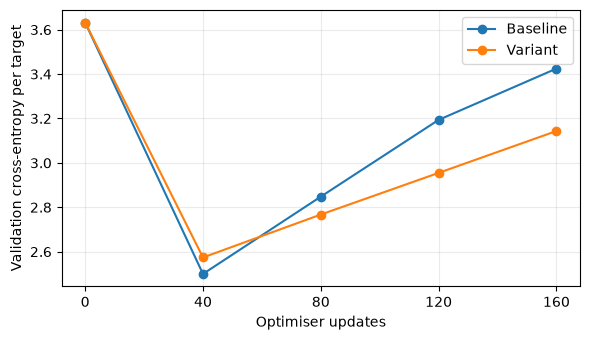

In [22]:
plt.figure(figsize=(6, 3.5))

for label, result in [
    ('Baseline', base_result),
    ('Variant', var_result)
]:
    plt.plot(
        [p['step'] for p in result['history']],
        [p['val_loss'] for p in result['history']],
        marker='o',
        label=label
    )

plt.xlabel('Optimiser updates')
plt.ylabel('Validation cross-entropy per target')
plt.xticks([0, 40, 80, 120, 160])
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig(EVIDENCE / 'validation_loss.png', dpi=140)
plt.show()

The two-head variant has lower validation loss at 160 updates (approximately 3.14) than the four-head baseline (3.42), contradicting my hypothesis. Both models reach their lowest recorded validation loss at 40 updates before it rises, suggesting overfitting as training continues. At update 40 the baseline is lower (2.4999 versus 2.5739), so the ranking reverses later in training. This single-seed result does not establish that two heads are generally better.

### Generated text before and after training

Both models use the same assigned prompt, greedy decoding and 40 new characters. The following cell displays their raw completions before and after training. repr preserves spaces and newline characters.

In [23]:
for label, result in [('Baseline', base_result), ('Variant', var_result)]:
    generated = result['generation']

    print(f'\n{label} | prompt: {generated["prompt"]!r}')
    print('Before training:', repr(generated['before']))
    print('After training: ', repr(generated['after']))


Baseline | prompt: 'the alpha lab '
Before training: 'the alpha lab m,\ng,\ngvmxiiiiiiiiiiiiiiiiiiiiiiiiiiiiii'
After training:  'the alpha lab opens at e.\natwelve.\n is open.\nin.\nsinel'

Variant | prompt: 'the alpha lab '
Before training: 'the alpha lab mxeka,\np,\npiiiiiiiiiiiiiiiiiiiiiiiiiiiii'
After training:  'the alpha lab opens at onele.\n ope.\nab is opetwe.\n.\n.\n'


### B1 Interpretation

My hypothesis about final validation loss was not supported. At 160 updates, the two-head variant achieved lower validation loss than the four-head baseline (3.1435 versus 3.4248) and higher validation accuracy (42.86% versus 41.31%). However, its final training loss was higher (0.2702 versus 0.2481), showing that fitting the training data more closely did not produce better validation performance.

Each attention head calculates its own scaled Q/K scores, applies the causal mask and softmax, and mixes its value vectors. Reducing the heads from four to two increases each head's width from 8 to 16 features while providing fewer separate attention distributions. Both models retain 14,718 parameters because the projection dimensions remain unchanged. Identical initial tensors and training-batch sequences were verified; the other training settings were controlled.

Both models reached their lowest recorded validation loss at update 40, after which validation loss increased while training loss continued falling, suggesting overfitting. At update 40, the baseline performed better (2.4999 versus 2.5739), but the ranking reversed by update 160. This shows that the comparison depends on the training stage. An alternative explanation is that the two-head variant fits the training templates less aggressively under this seed and update budget. Its higher final training loss is consistent with that explanation, but does not prove slower memorisation or establish why it generalises better. Additional seeds and evaluation data would help distinguish these possibilities.

Generated text became more notice-like after training. The baseline produced 'opens at e.', while the variant produced 'opens at onele.'. Both learned the phrase 'opens at', but their malformed time expressions show that neither model reliably generates valid notices. The variant's better validation metrics therefore do not establish reliable generation or language understanding.

The elapsed times in the table are not evidence that either model is faster: each is a single CPU measurement that includes evaluation and generation, and the baseline ran first, so its time can include warm-up. This investigation uses one assigned seed, a small synthetic corpus and a 24-character context. Validation shares vocabulary and room names with training, and overlapping windows reuse target characters. The conclusion is limited to this controlled run and held-out wording template; broader claims would require additional seeds and more varied independent evaluation data.

## B2 Architecture and comparison explanation

### B2 Explanation

My model is a causal decoder-style Transformer trained from random weights to predict the next character. It uses no pretrained model or encoder–decoder cross-attention.

TinyTransformer.embedding converts character IDs into vectors. The fixed sinusoidal pe buffer adds position information.
Inside Block, ln1 normalises the input before SeparateAttention. Independent q_proj, k_proj and v_proj layers create queries, keys and values. Each head calculates scaled dot-product scores, masks future positions and applies softmax before mixing values. The heads are joined and passed through proj.

The first residual connection adds the attention output to the block input. Block.ln2 and Block.ff then apply normalisation and a feed-forward transformation, followed by the second residual connection. TinyTransformer.norm and TinyTransformer.output produce raw vocabulary logits. Cross-entropy compares these logits with the shifted next-character targets.

For example, input 'the alpha lab opens at n' has target 'he alpha lab opens at ni'. The first position therefore predicts 'h' from 't'. Causal masking allows each position to use itself and earlier characters while preventing access to future input characters that could reveal its target.

After 160 updates, the four-head baseline achieved validation accuracy of 41.31%, while the two-head variant achieved 42.86%. These results measure individual character predictions on the synthetic validation set; they do not demonstrate general language understanding.

| Architecture | Information flow | Parallel training over known positions | Distant-context limitation |
|---|---|---|---|
| RNN | Each position receives a hidden state summarising earlier inputs. | The recurrent state depends on the previous position, so recurrent computation proceeds sequentially. | Earlier information must survive repeated hidden-state updates and may be lost. |
| Causal sequence CNN | Convolutions combine nearby current and earlier positions; stacking or dilation expands the receptive field. | Positions within a convolutional layer can be processed in parallel. | Inputs outside the receptive field cannot affect the prediction. |
| Causal Transformer | Each position directly attends to permitted positions in the supplied window. | Attention and feed-forward operations can process known positions in parallel within each layer, using a causal mask. | This implementation receives at most 24 characters and cannot directly attend to older text. |

Parallel training differs from autoregressive generation. During training, the input characters are already known, so the Transformer can calculate predictions for all positions together. During generation, each new character must be selected before it becomes input for the next prediction, so characters are generated sequentially.

The generation helper retains only the latest 24 characters. Once older characters leave this window, the model cannot directly retrieve them. It has no recurrent hidden state or separate memory preserving the complete history. Sinusoidal position indices restart
at zero for each cropped window.

Validation uses a held-out wording template, but it shares vocabulary and room names with training. Overlapping windows also reuse target characters, so those predictions are not independent observations. The results therefore support a limited comparison on synthetic lab notices, not reliable performance on arbitrary real-world text.

## AI and source log

| Tool / source | How it was used | How the work was checked |
|---|---|---|
| ST1520 Lab 3 notebook | Provided the model scaffold, synthetic corpus, fixed vocabulary, attention checks, and training, evaluation, generation and save/reload helpers. | Retained the lab structure and checked the adapted implementation using the notebook's assertions and recorded outputs. |
| ST1520 CA1 assignment brief | Used to identify the assigned seed, tensor dimensions, architecture comparison, training settings and submission requirements. | Compared the notebook's settings, sections and displayed evidence against the brief. |
| Claude (Anthropic) | Reviewed the notebook against the CA1 brief before submission, suggested corrections (removing leftover lab text, the duplicate prompt setting and the stale positions-on evidence file, and adding the update-40 comparison to B1 Interpretation) and applied the edits. | Reran the whole notebook with Restart and Run All and checked every quoted value against the new outputs and results.json. |
| ChatGPT (OpenAI) | Assisted with adapting and debugging code, organising cells, drafting and simplifying Markdown explanations, and validating my interpretation on the measured results. | Executed the code locally and checked tensor shapes, causal masking, boundary behaviour, repaired attention weights, training controls and reload agreement. Compared the drafted interpretations with the actual metrics, curves and generated text. |

ChatGPT contributed to simplifying and optimising both code and written explanations.
The reported experimental results are taken from my executed notebook.
The AI-generated suggestions were checked against the assignment
requirements, implementation and recorded evidence.